# Employee Attrition Prediction Using Apache Spark MLlib

### Big Data & Cloud-Based Machine Learning Project

**Technologies:** Apache Spark MLlib | AWS EC2 | AWS S3 | Google Colab

**Dataset:** IBM HR Analytics Employee Attrition Dataset

## 1. Project Objective

The objective of this project is to predict whether an employee is likely to leave an organization using employee-related attributes and machine learning.

The project uses Apache Spark MLlib for machine learning, Amazon S3 for data storage, and Amazon EC2 for Spark-based computation.

The final model uses Weighted Logistic Regression to handle the class imbalance in the attrition dataset.

## 2. Dataset

The project uses the IBM HR Analytics Employee Attrition dataset.

- **Total Records:** 1,470
- **Total Columns:** 35
- **Target Variable:** `Attrition`
- **Target Classes:** `Yes` and `No`

The dataset contains employee-related information such as age, job role, department, monthly income, job satisfaction, overtime, years at company, and other workplace attributes.

The `Attrition` column is used as the target variable for predicting whether an employee leaves the organization.

## 3. Cloud-Based Project Architecture

The project follows an end-to-end cloud-based machine learning workflow:

**Amazon S3 → Amazon EC2 → Apache Spark → Spark MLlib → Predictions → Amazon S3**

### Workflow

1. The employee attrition dataset is stored in **Amazon S3**.
2. **Amazon EC2** provides the computing environment for Apache Spark.
3. **Apache Spark** reads the dataset directly from S3 using the S3A filesystem.
4. The data is preprocessed using Spark MLlib feature transformation techniques.
5. A **Weighted Logistic Regression** model is trained using Spark MLlib.
6. The classification threshold is tuned to **0.4** to improve detection of attrition cases.
7. The final predictions and evaluation metrics are stored back in **Amazon S3**.
8. **Google Colab** is used to visualize and present the results.

## 4. Data Preprocessing

The dataset was prepared before applying the machine learning algorithm.

### Preprocessing Steps

- Removed unnecessary constant/identifier columns:
  - `EmployeeCount`
  - `Over18`
  - `StandardHours`
  - `EmployeeNumber`
- Converted categorical variables into numerical representations using **StringIndexer**.
- Applied **OneHotEncoder** to categorical features.
- Used **VectorAssembler** to combine numerical and encoded categorical features into a single `features` vector.
- Converted the target variable `Attrition` into a numerical `label`.
- Split the dataset into:
  - **80% Training Data**
  - **20% Testing Data**

The preprocessing pipeline was implemented using Apache Spark MLlib.

## 5. Exploratory Data Analysis

Exploratory Data Analysis was performed to understand employee attrition patterns and identify important factors associated with employees leaving the organization.

The visualizations below examine:

- Overall employee attrition distribution
- Relationship between overtime and attrition
- Attrition across different job roles
- Attrition across age groups
- Monthly income distribution by attrition

### 5.1 Employee Attrition Distribution

This visualization shows the distribution of employees who stayed with the organization versus employees who left.

The dataset contains more employees with **No Attrition** than **Attrition**, indicating a class imbalance in the target variable.

This imbalance was considered during model development by using **Weighted Logistic Regression**.

In [ ]:
import pandas as pd

df = pd.read_csv("employee_attrition.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


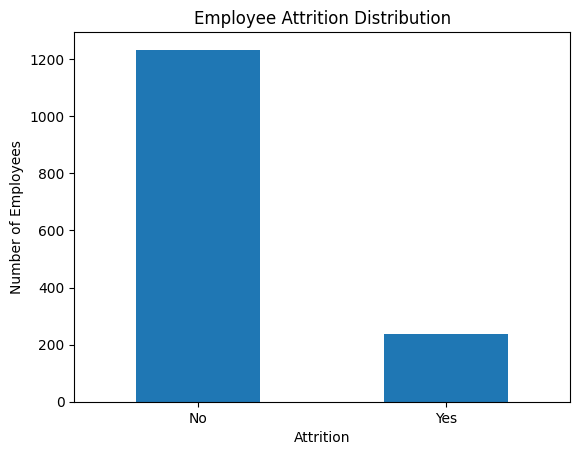

In [ ]:
import matplotlib.pyplot as plt

df["Attrition"].value_counts().plot(kind="bar")

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.show()


### 5.2 Employee Attrition by Overtime

This visualization compares employee attrition between employees who work overtime and those who do not.

Overtime is an important employee-related factor to examine because differences in attrition across overtime groups can provide useful HR insights.

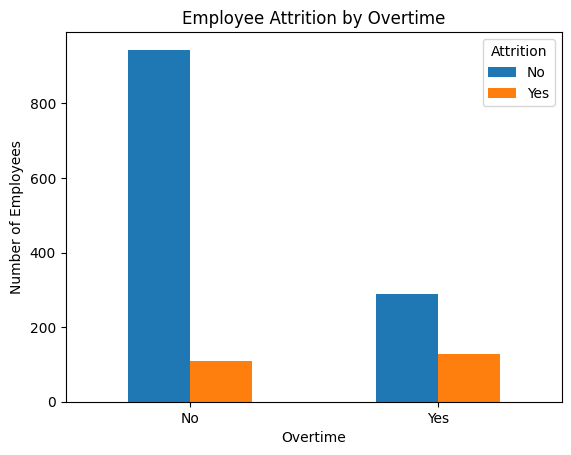

In [ ]:
import matplotlib.pyplot as plt

pd.crosstab(df["OverTime"], df["Attrition"]).plot(kind="bar")

plt.title("Employee Attrition by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.legend(title="Attrition")
plt.show()


### 5.3 Employee Attrition by Job Role

This visualization compares attrition across different employee job roles.

It helps identify job roles where the number of employees leaving is relatively higher and provides useful information for HR decision-making.

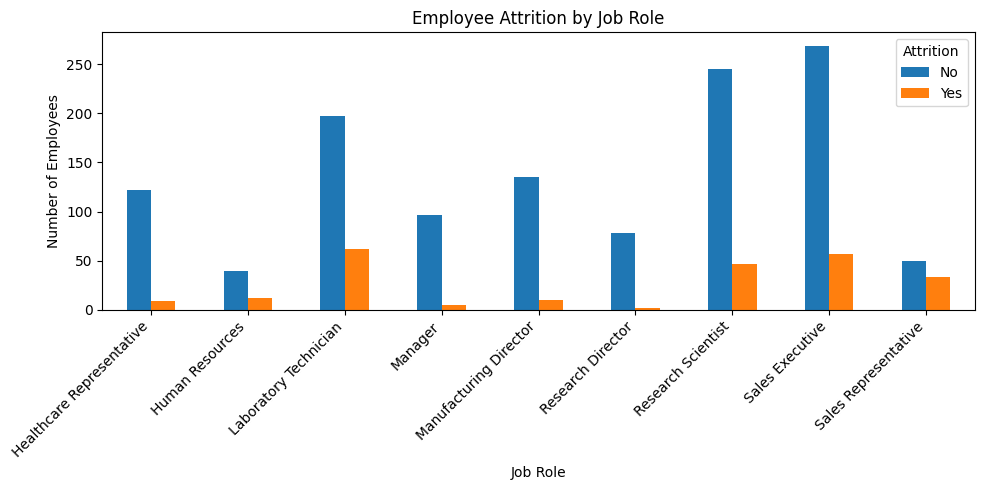

In [ ]:
pd.crosstab(df["JobRole"], df["Attrition"]).plot(kind="bar", figsize=(10, 5))

plt.title("Employee Attrition by Job Role")
plt.xlabel("Job Role")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Attrition")
plt.tight_layout()
plt.show()


### 5.4 Employee Attrition by Age Group

This visualization groups employees into different age ranges and compares attrition across those groups.

It helps identify whether attrition is concentrated in particular age groups and provides an additional perspective for understanding employee turnover.


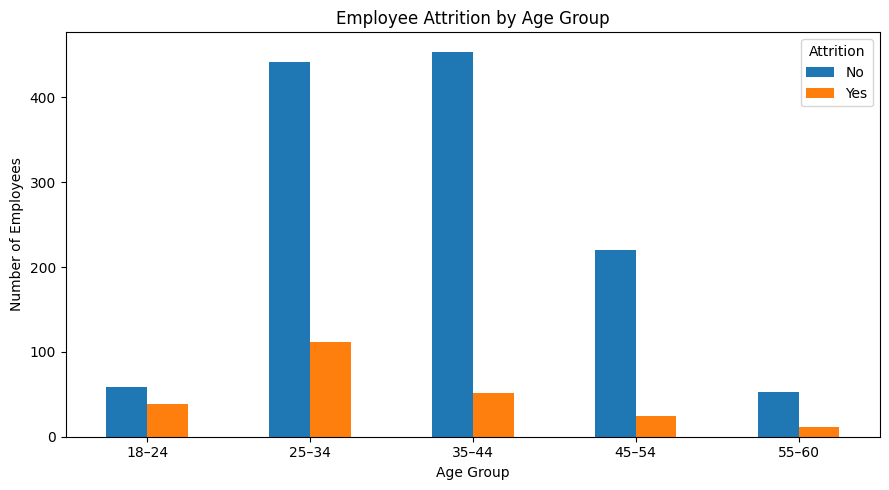

In [ ]:
age_bins = [18, 25, 35, 45, 55, 60]
age_labels = ["18–24", "25–34", "35–44", "45–54", "55–60"]

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

pd.crosstab(df["AgeGroup"], df["Attrition"]).plot(kind="bar", figsize=(9, 5))

plt.title("Employee Attrition by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.legend(title="Attrition")
plt.tight_layout()
plt.show()


### 6.1 Confusion Matrix

The confusion matrix evaluates the final model by comparing the actual employee attrition status with the predicted attrition status.

For the selected 0.4 threshold:

- **True Negative (TN):** 157
- **False Positive (FP):** 52
- **False Negative (FN):** 10
- **True Positive (TP):** 35

The model correctly identified **35 employees who experienced attrition** out of 45 actual attrition cases.

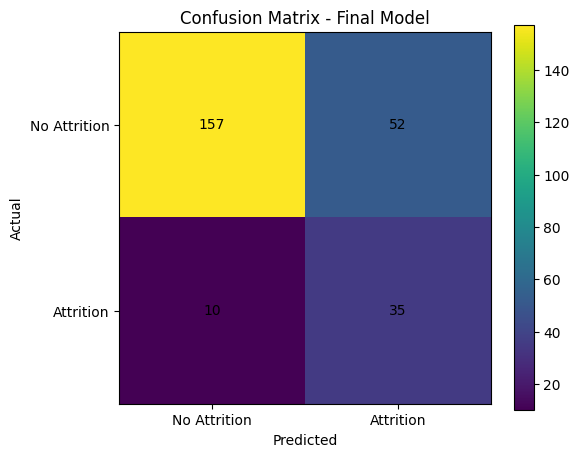

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

actual = [0]*157 + [0]*52 + [1]*10 + [1]*35
predicted = [0]*157 + [1]*52 + [0]*10 + [1]*35

cm = confusion_matrix(actual, predicted)

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Confusion Matrix - Final Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["No Attrition", "Attrition"])
plt.yticks([0, 1], ["No Attrition", "Attrition"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()


## 6. Machine Learning Model

A **Weighted Logistic Regression** classifier from Apache Spark MLlib was used to predict employee attrition.

### Why Weighted Logistic Regression?

The dataset contains significantly fewer attrition cases than non-attrition cases. Class weights were therefore applied during model training to give greater importance to the minority attrition class.

### Final Classification Threshold

The default classification threshold of **0.5** was evaluated along with thresholds **0.4** and **0.3**.

The **0.4 threshold** was selected because it achieved the highest Attrition F1-score among the tested thresholds while maintaining high attrition recall.

### 6.2 Classification Threshold Comparison

Different classification thresholds were evaluated to determine the best balance between identifying potential attrition cases and overall model performance.

| Threshold | Accuracy | Attrition Precision | Attrition Recall | Attrition F1 |
|---|---:|---:|---:|---:|
| 0.3 | 66.54% | 32.14% | 80.00% | 45.86% |
| **0.4** | **75.59%** | **40.23%** | **77.78%** | **53.03%** |
| 0.5 | 78.74% | 43.08% | 62.22% | 50.88% |

The **0.4 threshold** was selected because it produced the highest Attrition F1-score among the tested thresholds while maintaining strong attrition recall.

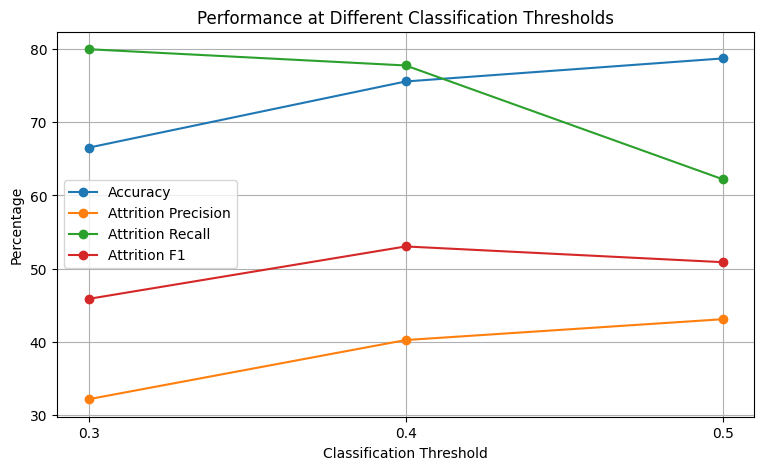

In [ ]:
thresholds = [0.3, 0.4, 0.5]

accuracy = [66.54, 75.59, 78.74]
precision = [32.14, 40.23, 43.08]
recall = [80.00, 77.78, 62.22]
f1 = [45.86, 53.03, 50.88]

plt.figure(figsize=(9, 5))

plt.plot(thresholds, accuracy, marker="o", label="Accuracy")
plt.plot(thresholds, precision, marker="o", label="Attrition Precision")
plt.plot(thresholds, recall, marker="o", label="Attrition Recall")
plt.plot(thresholds, f1, marker="o", label="Attrition F1")

plt.title("Performance at Different Classification Thresholds")
plt.xlabel("Classification Threshold")
plt.ylabel("Percentage")
plt.xticks(thresholds)
plt.legend()
plt.grid(True)
plt.show()

## 7. Final Model Performance

The final Weighted Logistic Regression model was evaluated using the selected classification threshold of **0.4**.

| Metric | Result |
|---|---:|
| Accuracy | **75.59%** |
| Attrition Precision | **40.23%** |
| Attrition Recall | **77.78%** |
| Attrition F1-Score | **53.03%** |

### Interpretation

The model identifies **77.78% of the employees who actually experienced attrition**.

Although the overall accuracy is 75.59%, accuracy alone is not sufficient for this problem because the dataset is imbalanced. Therefore, Attrition Recall and F1-Score were also considered when selecting the final threshold.

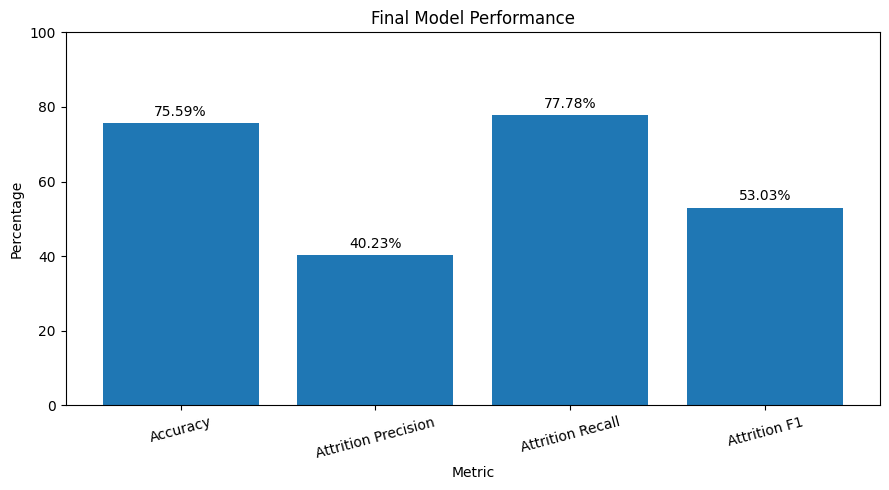

In [ ]:
metrics = {
    "Accuracy": 75.59,
    "Attrition Precision": 40.23,
    "Attrition Recall": 77.78,
    "Attrition F1": 53.03
}

plt.figure(figsize=(9, 5))
plt.bar(metrics.keys(), metrics.values())

plt.title("Final Model Performance")
plt.xlabel("Metric")
plt.ylabel("Percentage")
plt.ylim(0, 100)
plt.xticks(rotation=15)

for i, value in enumerate(metrics.values()):
    plt.text(i, value + 2, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()


## 9. Conclusion

This project demonstrates an end-to-end employee attrition prediction system using Apache Spark MLlib and AWS cloud services.

The employee dataset was stored in Amazon S3 and processed using Apache Spark running on Amazon EC2. Spark MLlib was used for feature preprocessing and Weighted Logistic Regression model training.

The final classification threshold was selected as **0.4**, achieving:

- **75.59% Accuracy**
- **40.23% Attrition Precision**
- **77.78% Attrition Recall**
- **53.03% Attrition F1-Score**

The trained model, final predictions, and evaluation metrics were stored in Amazon S3. Google Colab was used to visualize the dataset characteristics and model results.

The system can help organizations identify employees who may be at higher risk of attrition and support data-driven employee retention strategies.

## 10. Future Scope

The project can be further improved by:

- Testing additional Spark MLlib algorithms such as Random Forest and Gradient-Boosted Trees.
- Performing hyperparameter tuning to improve model performance.
- Using larger employee datasets for scalable experimentation.
- Deploying the trained model as a real-time prediction service.
- Integrating the system with an HR dashboard for continuous monitoring.
- Automating the S3 → EC2 → Spark MLlib prediction pipeline.
- Adding periodic retraining when new employee data becomes available.